# 01 · Bowling Speed Analysis

Work out a bowler's speed from a distance and a time, convert between units, and study a season of speed readings.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. The formula

$$\text{average speed} = \frac{\text{distance}}{\text{time}}$$

If a ball covers 18.9 m (popping crease to the far stumps) in 0.62 s, its average speed is 18.9 / 0.62 = 30.5 m/s.

This is an average speed, not a release speed. A cricket ball slows down through the air and loses more speed when it bounces, so the average over the whole flight is lower than the speed as it left the hand. A radar gun reads close to release speed. The two numbers are different quantities and should not be mixed.

### Unit conversions (exact)
| From | To metres / seconds |
|---|---|
| 1 foot | 0.3048 m |
| 1 yard | 0.9144 m |
| 1 millisecond | 0.001 s |

| Speed | Multiply m/s by |
|---|---|
| km/h | 3.6 |
| mph | 3600 / 1609.344 = 2.23694 |

In [2]:
# Write the calculation out by hand first, so every step is visible.
DISTANCE_TO_M = {"m": 1.0, "ft": 0.3048, "yd": 0.9144}
TIME_TO_S = {"s": 1.0, "ms": 0.001}

def speed_by_hand(distance, time, distance_unit="m", time_unit="s"):
    """Average speed in m/s, km/h and mph."""
    if distance <= 0 or time <= 0:
        raise ValueError("Distance and time must both be greater than zero.")
    metres = distance * DISTANCE_TO_M[distance_unit]
    seconds = time * TIME_TO_S[time_unit]
    ms = metres / seconds
    return {"m/s": ms, "km/h": ms * 3.6, "mph": ms * 3600 / 1609.344}

print(speed_by_hand(18.9, 0.62))
print(speed_by_hand(22, 500, "yd", "ms"))      # a full 22-yard pitch in half a second

{'m/s': 30.483870967741932, 'km/h': 109.74193548387096, 'mph': 68.19047729004548}
{'m/s': 40.2336, 'km/h': 144.84096000000002, 'mph': 90.00000000000001}


In [3]:
# The application uses pitchvision.speed.average_speed. Check that it gives exactly the same answers.
from pitchvision import speed

for args in [(18.9, 0.62, "m", "s"), (22, 500, "yd", "ms"), (62, 0.7, "ft", "s")]:
    mine = speed_by_hand(*args)
    app = speed.average_speed(*args)
    assert abs(mine["km/h"] - app["speed_kmh"]) < 1e-9 and abs(mine["mph"] - app["speed_mph"]) < 1e-9
    print(f"{args}: {app['speed_kmh']:.2f} km/h = {app['speed_mph']:.2f} mph   (kind: {app['kind']})")

# Bad input is rejected with a clear message rather than giving a silly answer.
try:
    speed.average_speed(18.9, 0)
except speed.SpeedInputError as e:
    print("Rejected:", e)

(18.9, 0.62, 'm', 's'): 109.74 km/h = 68.19 mph   (kind: average)
(22, 500, 'yd', 'ms'): 144.84 km/h = 90.00 mph   (kind: average)
(62, 0.7, 'ft', 's'): 97.19 km/h = 60.39 mph   (kind: average)
Rejected: Time must be greater than zero.


## 2. Load the speed readings

Each row is one timed delivery. `source` says how it was measured: `stopwatch` rows have a distance and a time; `radar` rows only have the radar's km/h figure.

In [4]:
readings = pd.read_csv(DATA / "speeds.csv", parse_dates=["date"])
print(len(readings), "readings for", readings["player"].nunique(), "bowlers")
readings.head()

224 readings for 8 bowlers


,player,date,source,distance_m,time_s,kmh,synthetic
0,Ethan Brooks,2025-04-29,stopwatch,18.9,1.121,60.7,True
1,Ethan Brooks,2025-04-29,stopwatch,18.9,1.096,62.1,True
2,Ethan Brooks,2025-04-29,stopwatch,18.9,1.148,59.3,True
3,Ethan Brooks,2025-04-29,stopwatch,18.9,1.130,60.2,True
4,Ethan Brooks,2025-04-29,stopwatch,18.9,1.157,58.8,True


### Missing data

Some stopwatch rows have no time recorded. We cannot work out a speed for those, so they are counted and left out. We never fill in a guessed value.

In [5]:
stopwatch = readings[readings["source"] == "stopwatch"].copy()
missing = stopwatch["time_s"].isna().sum()
print(f"{missing} stopwatch readings have no time and are left out.")
stopwatch = stopwatch.dropna(subset=["time_s", "distance_m"])

# Recalculate every speed from distance and time, and compare with the km/h stored in the file.
stopwatch["kmh_calc"] = stopwatch["distance_m"] / stopwatch["time_s"] * 3.6
print("Largest difference from the stored value:", (stopwatch["kmh_calc"] - stopwatch["kmh"]).abs().max().round(2), "km/h (rounding)")
radar = readings[readings["source"] == "radar"].dropna(subset=["kmh"])

1 stopwatch readings have no time and are left out.
Largest difference from the stored value: 0.14 km/h (rounding)


## 3. Speed statistics per bowler

The mean is the sum of the readings divided by how many there are. The standard deviation says how spread out they are, so a small value means the bowler's pace is consistent. The table also gives the fastest, slowest and latest reading.

In [6]:
summary = (stopwatch.sort_values("date").groupby("player")["kmh_calc"]
           .agg(readings="count", average="mean", fastest="max", slowest="min", spread="std", recent="last")
           .round(1).sort_values("average", ascending=False))
summary

,readings,average,fastest,slowest,spread,recent
player,,,,,,
Imran Khan,23,102.9,108.9,97.9,3.3,97.9
Jack Wood,24,95.1,100.5,91.6,2.6,95.6
Farhan Ali,24,91.8,96.9,87.1,2.2,94.1
Liam Shaw,24,90.7,98.3,84.9,3.3,87.0
Milan Das,24,87.8,94.4,82.8,2.9,87.5
Kabir Rao,24,64.1,69.2,58.5,2.6,63.2
George Hill,24,61.7,64.7,56.3,2.0,63.8
Ethan Brooks,24,60.2,64.9,55.3,2.2,64.9


In [7]:
# Same figures from the shared module (this is what the Bowling Lab shows).
name = summary.index[0]
vals = stopwatch[stopwatch["player"] == name].sort_values("date")["kmh_calc"].tolist()
s = speed.speed_summary(vals)
print(name, {k: round(v, 1) if isinstance(v, float) else v for k, v in s.items()})
assert abs(s["average"] - summary.loc[name, "average"]) < 0.06

Imran Khan {'count': 23, 'average': 102.9, 'max': 108.9, 'min': 97.9, 'recent': 97.9, 'median': 103.1, 'std_dev': 3.3}


## 4. Speed distributions

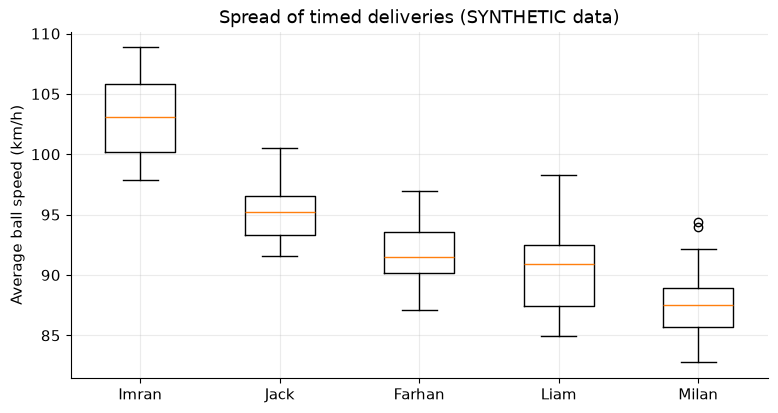

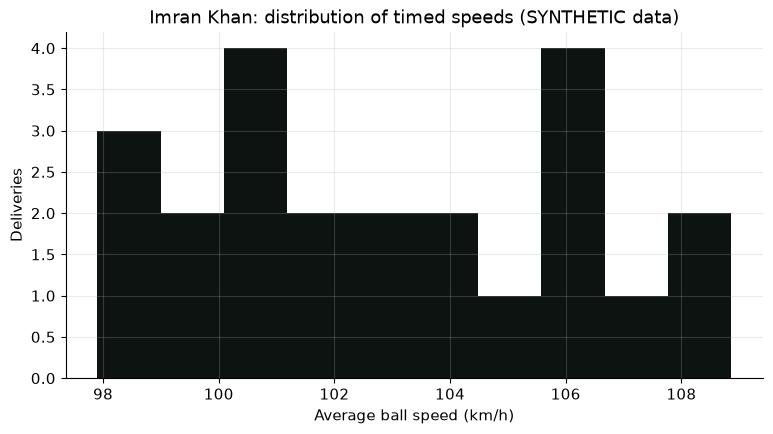

In [8]:
pace = summary.head(5).index
fig, ax = plt.subplots()
ax.boxplot([stopwatch.loc[stopwatch["player"] == p, "kmh_calc"] for p in pace])
ax.set_xticklabels([p.split()[0] for p in pace])      # works on old and new matplotlib
ax.set_ylabel("Average ball speed (km/h)")
ax.set_title("Spread of timed deliveries (SYNTHETIC data)")
plt.show()

fig, ax = plt.subplots()
ax.hist(stopwatch.loc[stopwatch["player"] == name, "kmh_calc"], bins=10, color=INK)
ax.set_xlabel("Average ball speed (km/h)"); ax.set_ylabel("Deliveries")
ax.set_title(f"{name}: distribution of timed speeds (SYNTHETIC data)")
plt.show()

## 5. Speed over the season

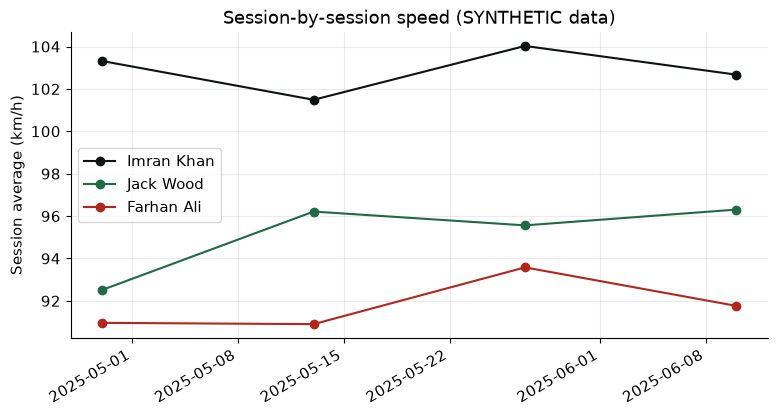

Imran Khan: change from the first third to the last third of readings = -0.4 km/h


In [9]:
by_session = stopwatch.groupby(["player", "date"])["kmh_calc"].mean().reset_index()
fig, ax = plt.subplots()
for p, colour in zip(pace[:3], [INK, GREEN, RED]):
    d = by_session[by_session["player"] == p]
    ax.plot(d["date"], d["kmh_calc"], marker="o", color=colour, label=p)
ax.set_ylabel("Session average (km/h)"); ax.set_title("Session-by-session speed (SYNTHETIC data)"); ax.legend()
fig.autofmt_xdate(); plt.show()

trend = speed.speed_trend(vals)
print(f"{name}: change from the first third to the last third of readings = {trend['change_first_to_last_third']:+.1f} km/h")

## 6. Radar against stopwatch

Where a bowler has both kinds of reading on the same day we can compare them. We expect the radar figure to be higher, because it is taken near release and the stopwatch figure is an average over the whole flight.

Days with both kinds of reading: 32
Radar reads higher by 10.9 km/h on average
Timed (average) speed is 88.3 % of the radar speed


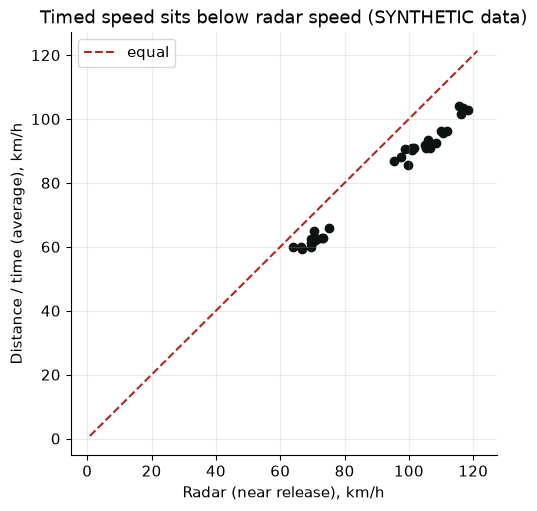

Saved /Users/sahasreddy/Documents/Cricket/notebooks/exports/bowling_speed_summary.csv


In [10]:
sw_day = stopwatch.groupby(["player", "date"])["kmh_calc"].mean().rename("stopwatch_kmh")
rd_day = radar.groupby(["player", "date"])["kmh"].mean().rename("radar_kmh")
both = pd.concat([sw_day, rd_day], axis=1).dropna()
both["difference"] = both["radar_kmh"] - both["stopwatch_kmh"]
both["stopwatch as % of radar"] = both["stopwatch_kmh"] / both["radar_kmh"] * 100
print("Days with both kinds of reading:", len(both))
print("Radar reads higher by", round(both["difference"].mean(), 1), "km/h on average")
print("Timed (average) speed is", round(both["stopwatch as % of radar"].mean(), 1), "% of the radar speed")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(both["radar_kmh"], both["stopwatch_kmh"], color=INK)
lims = [both.min().min() - 3, both[["radar_kmh", "stopwatch_kmh"]].max().max() + 3]
ax.plot(lims, lims, "--", color=RED, label="equal")
ax.set_xlabel("Radar (near release), km/h"); ax.set_ylabel("Distance / time (average), km/h")
ax.set_title("Timed speed sits below radar speed (SYNTHETIC data)"); ax.legend(); plt.show()

summary.to_csv(EXPORTS / "bowling_speed_summary.csv")
print("Saved", EXPORTS / "bowling_speed_summary.csv")

## Summary

### Key findings
- Average speed is distance divided by time; the unit conversions are exact constants.
- The hand calculation and `pitchvision.speed` agree to nine decimal places.
- In the synthetic data the timed speed is about 88% of the radar speed, because that is how the sample was generated.

### Interpretation
A timed speed is useful for tracking one bowler against themselves using the same method each time. It is not comparable with a radar reading or with speeds quoted on television.

### Limitations
- A hand-held stopwatch has a reaction-time error of about 0.1-0.2 s, which is large next to a 0.6 s flight. Timing from high-frame-rate video is far better.
- The measured distance must be the real distance the ball travelled.
- The ratio between average and release speed varies with length and pitch; do not use a fixed factor to 'convert' one into the other.
- All figures shown come from synthetic data.

### How this notebook connects to the application
The Bowling Lab's speed calculator calls `pitchvision.speed.average_speed` through `POST /api/speed/calculate`; the history, average, fastest, slowest and most recent figures come from `speed_summary`; the radar comparison uses `compare_radar_to_estimate`. The browser's live calculator uses the same constants and is tested against the same known values.